In [2]:
#Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("rain.csv")
df

,Statistic Label,Day,Meteorological Weather Station,UNIT,VALUE
0,Precipitation Amount,2010 January 01,Dublin Airport,Millimetres,2.6
1,Precipitation Amount,2010 January 02,Dublin Airport,Millimetres,0.2
2,Precipitation Amount,2010 January 03,Dublin Airport,Millimetres,0.1
3,Precipitation Amount,2010 January 04,Dublin Airport,Millimetres,0.2
4,Precipitation Amount,2010 January 05,Dublin Airport,Millimetres,0.6
...,...,...,...,...,...
6082,Precipitation Amount,2026 August 27,Dublin Airport,Millimetres,14.6
6083,Precipitation Amount,2026 August 28,Dublin Airport,Millimetres,3.5
6084,Precipitation Amount,2026 August 29,Dublin Airport,Millimetres,3.2
6085,Precipitation Amount,2026 August 30,Dublin Airport,Millimetres,11.6


In [4]:
df.shape

(6087, 5)

In [5]:
df.head()

,Statistic Label,Day,Meteorological Weather Station,UNIT,VALUE
0,Precipitation Amount,2010 January 01,Dublin Airport,Millimetres,2.6
1,Precipitation Amount,2010 January 02,Dublin Airport,Millimetres,0.2
2,Precipitation Amount,2010 January 03,Dublin Airport,Millimetres,0.1
3,Precipitation Amount,2010 January 04,Dublin Airport,Millimetres,0.2
4,Precipitation Amount,2010 January 05,Dublin Airport,Millimetres,0.6


In [6]:
df.tail()

,Statistic Label,Day,Meteorological Weather Station,UNIT,VALUE
6082,Precipitation Amount,2026 August 27,Dublin Airport,Millimetres,14.6
6083,Precipitation Amount,2026 August 28,Dublin Airport,Millimetres,3.5
6084,Precipitation Amount,2026 August 29,Dublin Airport,Millimetres,3.2
6085,Precipitation Amount,2026 August 30,Dublin Airport,Millimetres,11.6
6086,Precipitation Amount,2026 August 31,Dublin Airport,Millimetres,0.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6087 entries, 0 to 6086
Data columns (total 5 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Statistic Label                 6087 non-null   str    
 1   Day                             6087 non-null   str    
 2   Meteorological Weather Station  6087 non-null   str    
 3   UNIT                            6087 non-null   str    
 4   VALUE                           6087 non-null   float64
dtypes: float64(1), str(4)
memory usage: 589.3 KB


In [8]:
df.isnull().sum()

Statistic Label                   0
Day                               0
Meteorological Weather Station    0
UNIT                              0
VALUE                             0
dtype: int64

In [9]:
df.describe()

,VALUE
count,6087.000000
mean,2.109627
std,4.450533
min,0.000000
25%,0.000000
50%,0.200000
75%,2.300000
max,84.000000


In [10]:
df.describe(include=['str'])

,Statistic Label,Day,Meteorological Weather Station,UNIT
count,6087,6087,6087,6087
unique,1,6087,1,1
top,Precipitation Amount,2010 January 01,Dublin Airport,Millimetres
freq,6087,1,6087,6087


In [11]:
df.describe(include='all')

,Statistic Label,Day,Meteorological Weather Station,UNIT,VALUE
count,6087,6087,6087,6087,6087.000000
unique,1,6087,1,1,NaN
top,Precipitation Amount,2010 January 01,Dublin Airport,Millimetres,NaN
freq,6087,1,6087,6087,NaN
mean,NaN,NaN,NaN,NaN,2.109627
std,NaN,NaN,NaN,NaN,4.450533
min,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,0.200000
75%,NaN,NaN,NaN,NaN,2.300000


In [12]:
mean= df['VALUE'].mean()
print(mean)

2.109627074092328


In [13]:
median= df['VALUE'].median()
print(median)

0.2


In [14]:
mode= df['VALUE'].mode()
print(mode)

0    0.0
Name: VALUE, dtype: float64


In [15]:
minimum = df['VALUE'].min()
maximum = df['VALUE'].max()
print(minimum, maximum)

0.0 84.0


In [16]:
range_rain = maximum-minimum
print(range_rain)

84.0


In [17]:
variance_rain = df['VALUE'].var()
print (variance_rain)

19.807245457354284


In [18]:
std_rain= df['VALUE'].std()
print(std_rain)

4.450533165515598


In [19]:
Q1= df['VALUE'].quantile(0.25)
Q2= df['VALUE'].quantile(0.5)
Q3= df['VALUE'].quantile(0.75)
IQR = Q3-Q1
print(Q1,Q2,Q3,IQR)

0.0 0.2 2.3 2.3


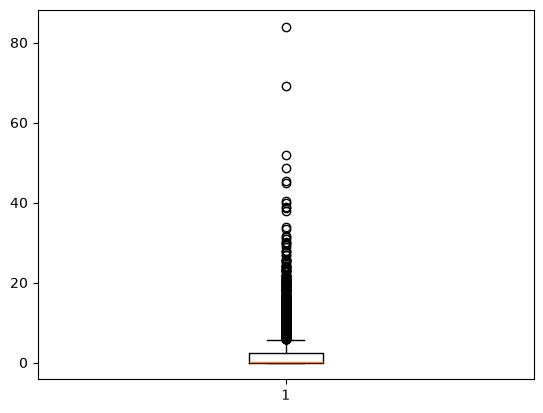

In [22]:
plt.boxplot(df['VALUE'])
plt.show()

In [23]:
skewness_rain= df['VALUE'].skew()
print(skewness_rain)

4.971725629553603


In [25]:
kurtosis_rain=df['VALUE'].kurt()
print(kurtosis_rain)

45.39272291375642


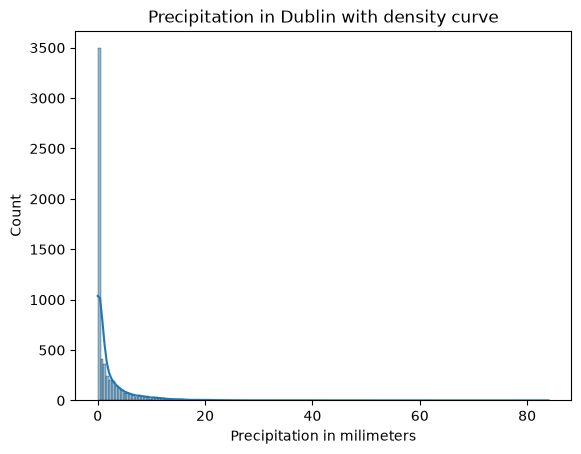

In [31]:
sns.histplot(df['VALUE'], kde=True)
plt.xlabel('Precipitation in milimeters')
plt.title('Precipitation in Dublin with density curve')
plt.show()

In [32]:
df['rain_category']= np.where(df['VALUE']==0, 'Dry',
                np.where(df['VALUE']<=2.5, 'Light',
                np.where(df['VALUE']<=10.0, 'Moderate', 'Heavy')))

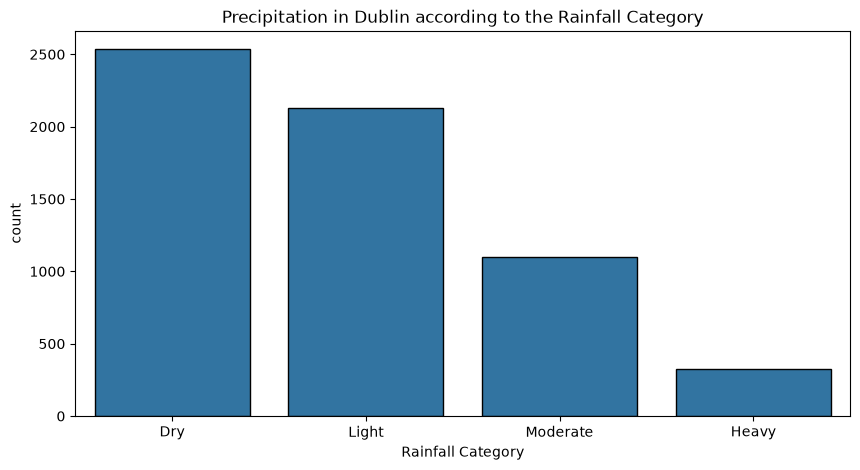

In [42]:
labels=['Dry', 'Light', 'Moderate', 'Heavy']
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='rain_category', order=labels, edgecolor='black')
plt.title('Precipitation in Dublin according to the Rainfall Category')
plt.xlabel('Rainfall Category')
plt.show()

In [60]:
exact_counts=df['rain_category'].value_counts()
print(exact_counts)

rain_category
Dry         2534
Light       2130
Moderate    1101
Heavy        322
Name: count, dtype: int64


In [64]:
#Define number of trials and success probability
p_success= (df['VALUE']>0).mean()
n_trials= 30 #number of days 

print(p_success)

0.583702973550189


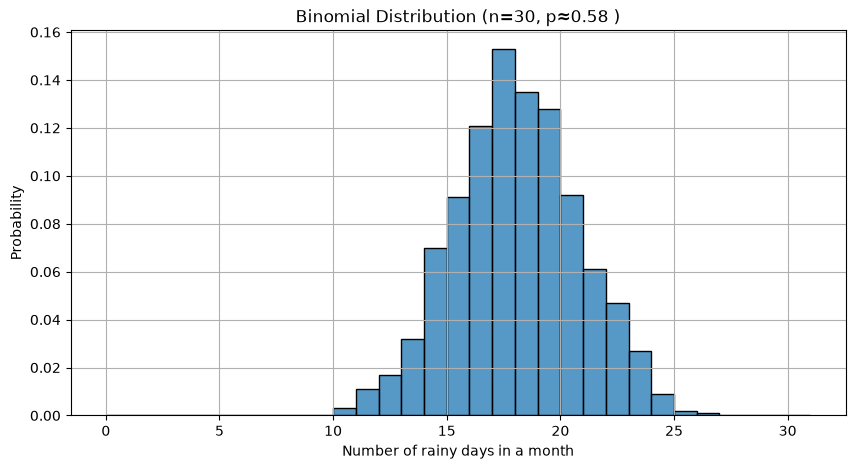

In [65]:
#Generate binomial distribution data
binomial_data= np.random.binomial(n_trials, p_success, 1000)

#plot
plt.figure(figsize=(10,5))
sns.histplot(binomial_data, bins=range(n_trials +2), kde=False, stat='probability')
plt. title('Binomial Distribution (n=30, p≈0.58 )')
plt.xlabel('Number of rainy days in a month')
plt.ylabel('Probability')
plt.grid()
plt.show()

In [77]:
df['datetime']=pd.to_datetime(df['Day'], format='%Y %B %d')

df['Year']=df['datetime'].dt.year
df['Month']=df['datetime'].dt.month

In [78]:
from scipy.stats import poisson

#Parameters
df['rain_heavy']=np.where(df['rain_category']=='Heavy', 1, 0)

lambda_rate=df.groupby(['Year','Month'])['rain_heavy'].sum().mean()
k=np.arange(0,10)
print(lambda_rate)



1.61


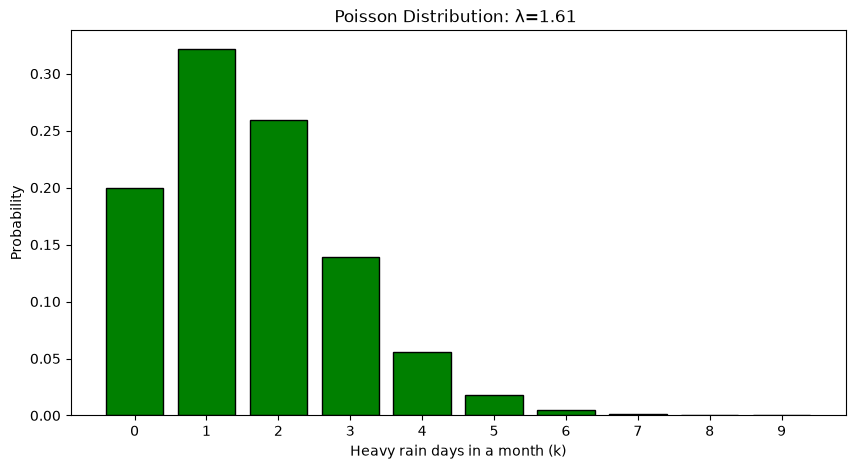

In [73]:
poisson_pmf= poisson.pmf(k, lambda_rate)

plt.figure(figsize=(10,5))
plt.bar(k, poisson_pmf, color='green', edgecolor='black')
plt.title('Poisson Distribution: λ=1.61 ')
plt.xlabel('Heavy rain days in a month (k)')
plt.ylabel('Probability')
plt.xticks(k)
plt.show()

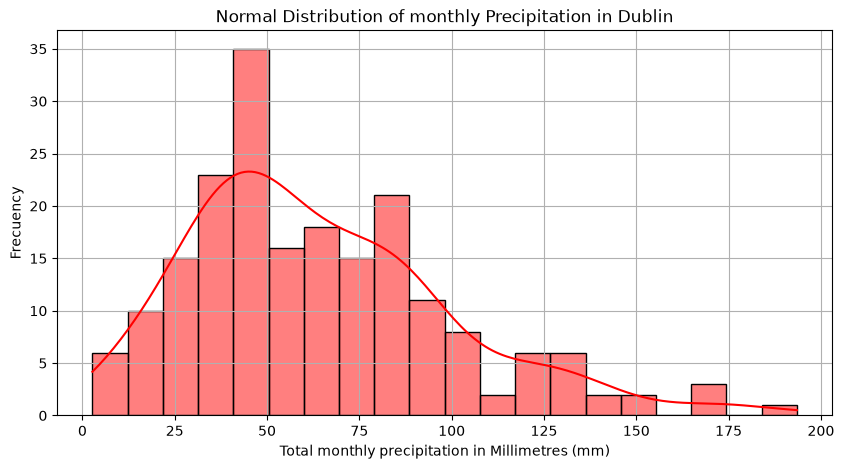

In [76]:
monthly_rain=df.groupby(['Year','Month'])['VALUE'].sum()
plt.figure(figsize=(10,5))
sns.histplot(monthly_rain, bins=20, kde=True, color='Red', edgecolor='black')
plt.title('Normal Distribution of monthly Precipitation in Dublin')
plt.xlabel('Total monthly precipitation in Millimetres (mm)')
plt.ylabel('Frecuency')
plt.grid()
plt.show()